# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
from aitlas.datasets import HRSIDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

In [ ]:
dataset_config = {
    "data_dir": "./data/HRSID/JPEGImages/",
    "annotation_dir": "./data/HRSID/annotations/train_test2017.json",
}
dataset = HRSIDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 5604


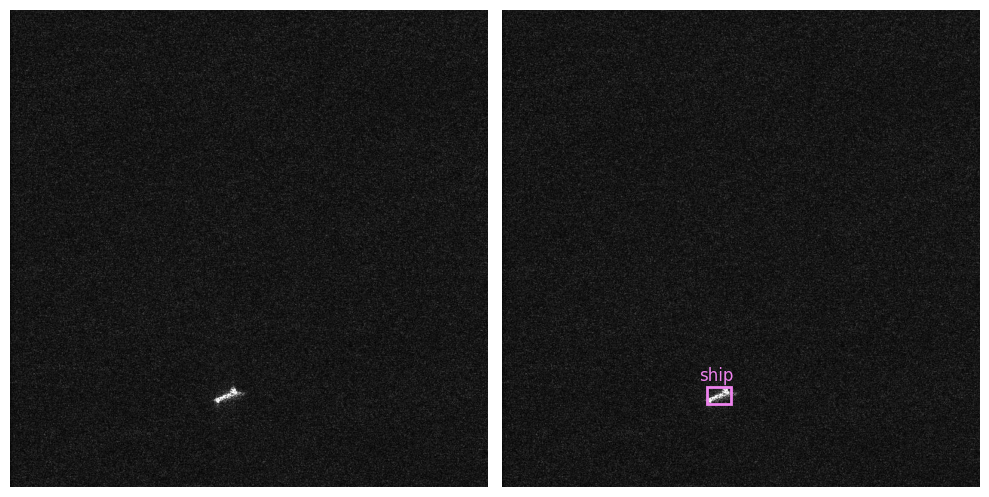

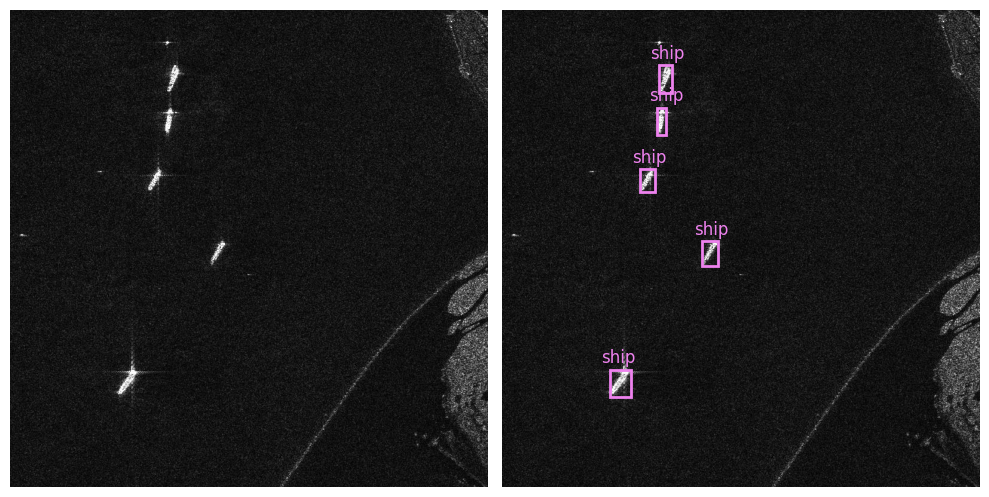

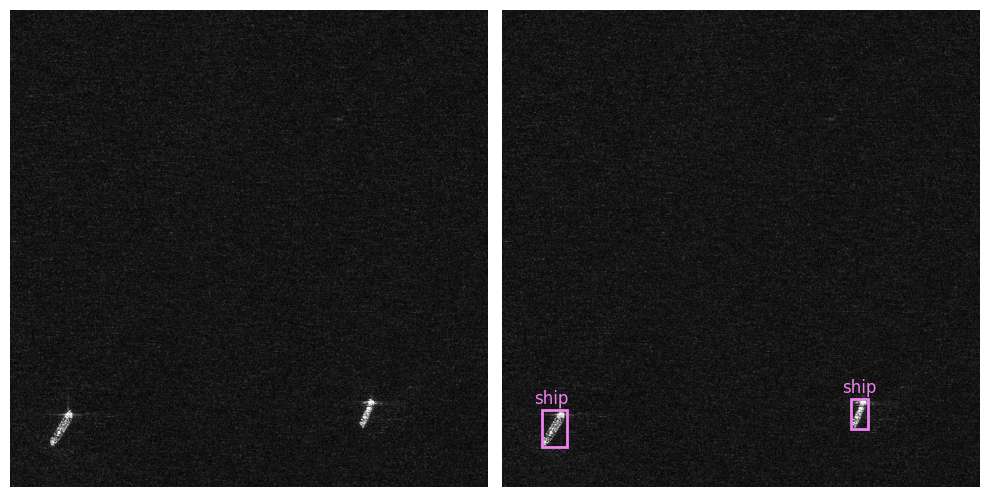

In [22]:
fig1 = dataset.show_image(5)
fig2 = dataset.show_image(10)
fig3 = dataset.show_image(100);

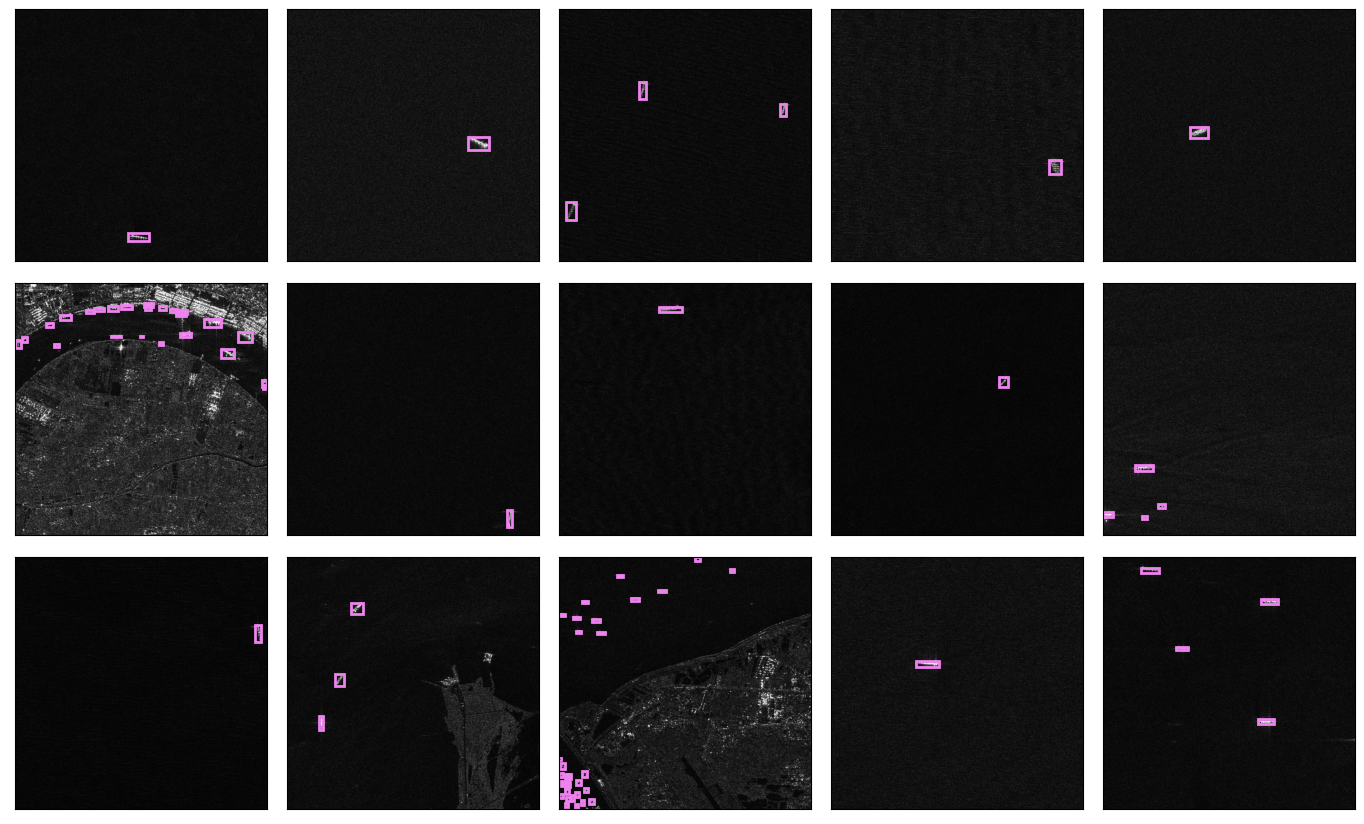

In [ ]:
fig = dataset.show_batch(15);

In [23]:
dataset.data_distribution_table()

,Label,Count
0,ship,16951


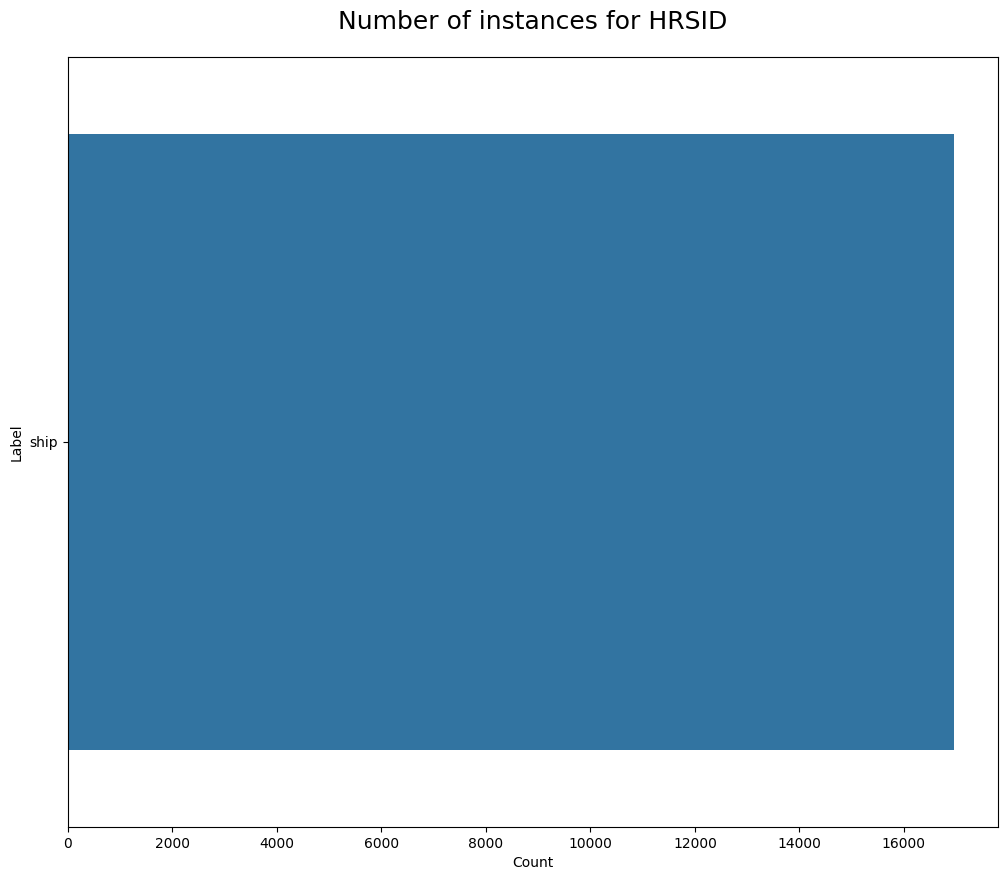

In [ ]:
fig = dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/HRSID/JPEGImages",
    "annotation_dir": "./data/HRSID/annotations/train_test2017.json",
    "csv_file": "./data/HRSID/hrsid_train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = HRSIDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 3363


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/hrsid"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [30]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2026-01-12 14:10:23,923 INFO Starting training.
training: 100%|██████████| 421/421 [02:18<00:00,  3.04it/s]
2026-01-12 14:12:42,315 INFO epoch: 1, time: 139, loss:  0.18748
testing on train set: 100%|██████████| 421/421 [01:13<00:00,  5.76it/s]
2026-01-12 14:14:07,326 INFO map:0.5980828404426575, map_50:0.8499841690063477, map_75:0.7124137878417969, map_small:0.5918983221054077, map_medium:0.6666807532310486, map_large:0.5142366290092468, mar_1:0.27270036935806274, mar_10:0.583512008190155, mar_100:0.6618785262107849, mar_small:0.6546598672866821, mar_medium:0.7363938093185425, mar_large:0.6098591685295105, map_per_class:0.5980828404426575, mar_100_per_class:0.6618785262107849, classes:1.0
training: 100%|██████████| 421/421 [02:20<00:00,  3.00it/s]
2026-01-12 14:16:27,505 INFO epoch: 2, time: 140, loss:  0.13615
testing on train set: 100%|██████████| 421/421 [01:13<00:00,  5.72it/s]
2026-01-12 14:17:49,181 INFO map:0.6576265096664429, map_50:0.8976334929466248, map_75:0.781700611114502

0.06260749335458085

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/HRSID/JPEGImages",
    "annotation_dir": "./data/HRSID/annotations/train_test2017.json",
    "csv_file": "./data/HRSID/hrsid_val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = HRSIDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/hrsid/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 1121


2026-01-13 07:46:16,213 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/hrsid/checkpoint.pth.tar
2026-01-13 07:46:16,554 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/hrsid/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 141/141 [00:24<00:00,  5.78it/s]


[{'map': 0.6579036116600037,
  'map_50': 0.8849250674247742,
  'map_75': 0.7839875221252441,
  'map_small': 0.65392005443573,
  'map_medium': 0.7165332436561584,
  'map_large': 0.429641991853714,
  'mar_1': 0.2725529968738556,
  'mar_10': 0.6063026189804077,
  'mar_100': 0.7083647847175598,
  'mar_small': 0.7031130790710449,
  'mar_medium': 0.7802157998085022,
  'mar_large': 0.5235294103622437,
  'map_per_class': 0.6579036116600037,
  'mar_100_per_class': 0.7083647847175598,
  'classes': 1.0}]

## Predictions

2026-01-13 07:46:48,694 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/hrsid/checkpoint.pth.tar
2026-01-13 07:46:49,042 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/hrsid/checkpoint.pth.tar at epoch 11


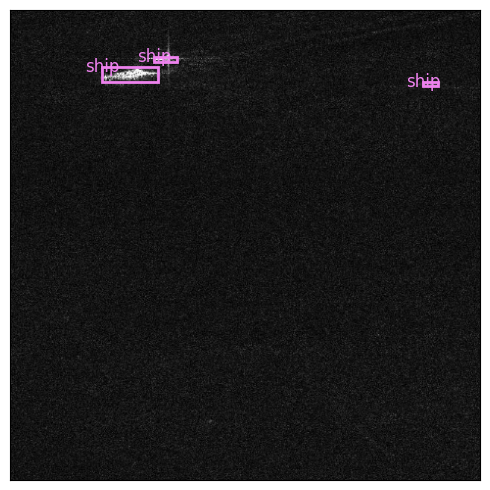

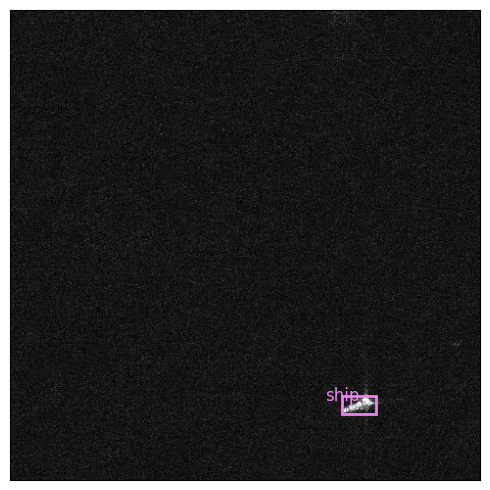

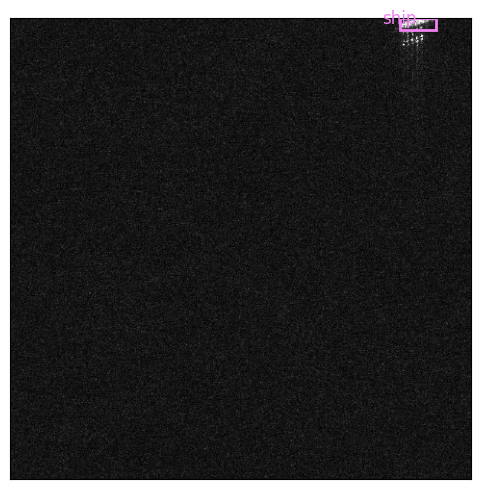

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/hrsid/checkpoint.pth.tar"
labels = ["no-data","ship"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/HRSID/JPEGImages/P0001_0_800_10190_10990.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/HRSID/JPEGImages/P0001_3000_3800_1800_2600.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/HRSID/JPEGImages/P0001_4800_5600_1800_2600.jpg')
fig = model.detect_objects(image, labels, transform)